## RQ1: How does traffic accident severity related to posted speed limits in Victorian roads, given accidents happen.

### Data:
- `rq1.parquet` generated by `data.ipynb`, put under same dir as this notebook

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import pyarrow
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, average_precision_score, balanced_accuracy_score)

THE_ANSWER = 42

### Output style (optional)

In [2]:
plt.style.use("tableau-colorblind10")
import matplotlib as mpl
from matplotlib import font_manager
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
if ("IBM Plex Mono" in available_fonts):
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["IBM Plex Mono"],
        "font.monospace": ["IBM Plex Mono"],
        "axes.unicode_minus": False,
        "font.size": 12,
        "figure.dpi": 120,
    })

### Data check

In [3]:
df = pd.read_parquet("rq1.parquet")
print(df.shape)

assert(df.shape == (195523, 98))

(195523, 98)


### Data description

In [4]:
df.isna().sum().sort_values(ascending=False).head(30)

SPEED_ZONE                14476
RMA                        8690
ROAD_TYPE                  2555
ROAD_TYPE_INT              2361
DEG_URBAN_NAME              906
NODE_TYPE                     5
ACCIDENT_TYPE                 0
ACCIDENT_NO                   0
DCA_CODE                      0
LIGHT_CONDITION               0
ROAD_GEOMETRY                 0
SEVERITY                      0
NODE_ID                       0
NO_OF_VEHICLES                0
atmos_clear                   0
atmos_not_known               0
atmos_strong_winds            0
atmos_raining                 0
atmos_fog                     0
atmos_snowing                 0
atmos_dust                    0
atmos_smoke                   0
surface_dry                   0
surface_wet                   0
surface_unknown               0
surface_muddy                 0
surface_icy                   0
surface_snowy                 0
vehicle_type_Bicycle          0
vehicle_type_Bus/Coach        0
dtype: int64

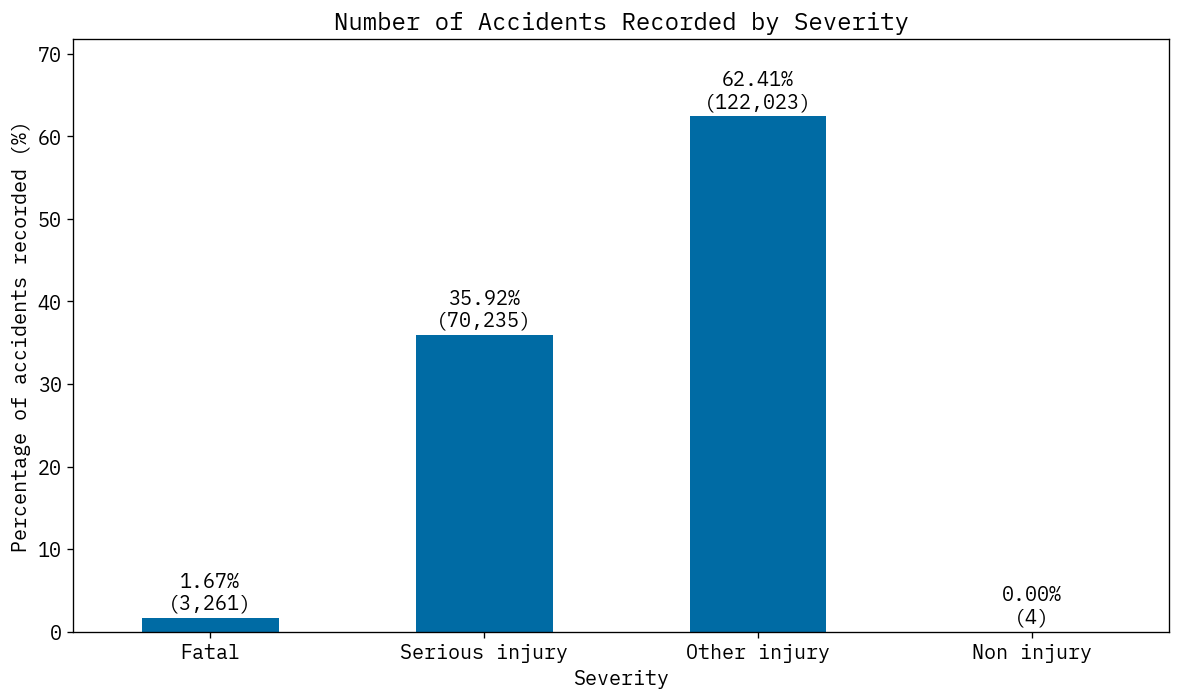

In [5]:
sev_counts = df["SEVERITY"].value_counts(dropna=False).sort_index()
sev_pct = df["SEVERITY"].value_counts(normalize=True, dropna=False).sort_index() * 100
labels = [
    "Fatal",
    "Serious injury",
    "Other injury",
    "Non injury",
]
plt.figure(figsize=(10, 6))
ax = sev_pct.plot(kind="bar")
ax.bar_label(
    ax.containers[0],
    labels=[f"{sev_pct.values[i]:.2f}%\n({int(sev_counts.values[i]):,})" for i in range(len(sev_counts.values))],
    padding=3
)
ax.set_ylim(0, sev_pct.max() * 1.15)
plt.xlabel("Severity")
plt.ylabel("Percentage of accidents recorded (%)")
plt.title("Number of Accidents Recorded by Severity")
plt.xticks(ticks=range(len(labels)), labels=labels, rotation=0)
plt.tight_layout()
plt.savefig("acc_by_sev.png", dpi=300)
plt.show()

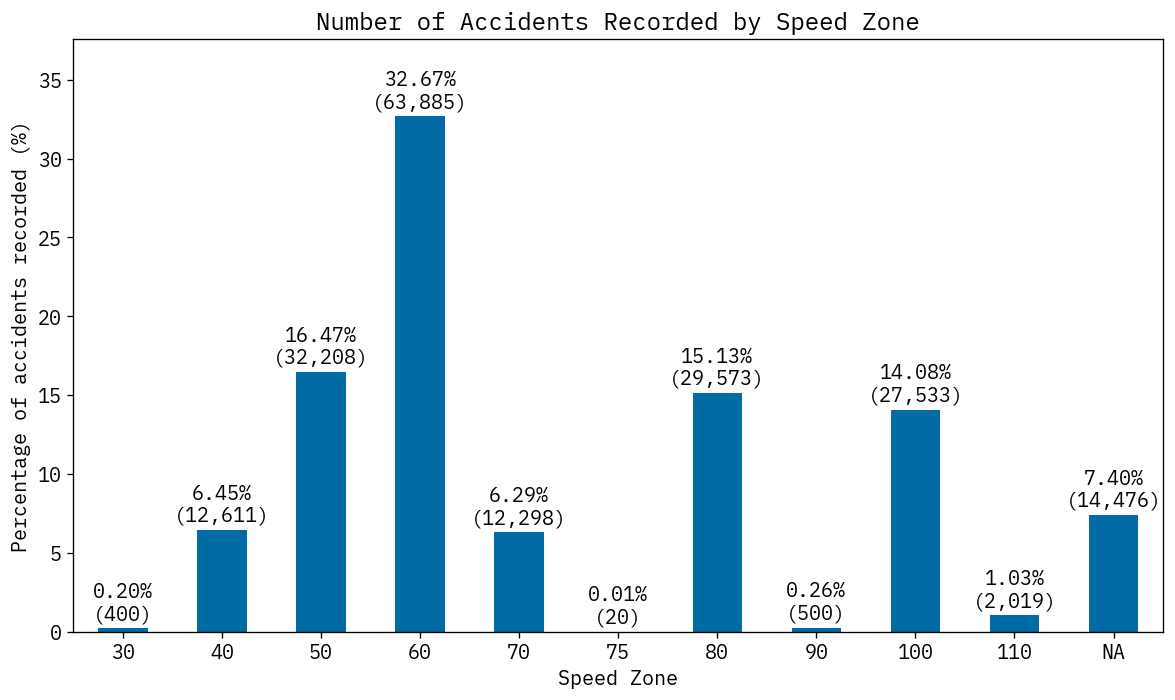

In [6]:
spd_counts = df["SPEED_ZONE"].value_counts(dropna=False).sort_index()
spd_pct = df["SPEED_ZONE"].value_counts(normalize=True, dropna=False).sort_index() * 100
labels = [
    "NA" if pd.isna(x) else str(int(x))
    for x in spd_counts.index
]
plt.figure(figsize=(10, 6))
ax = spd_pct.plot(kind="bar")
ax.bar_label(
    ax.containers[0],
    labels=[f"{spd_pct.values[i]:.2f}%\n({int(spd_counts.values[i]):,})" for i in range(len(spd_counts.values))],
    padding=3
)
ax.set_ylim(0, spd_pct.max() * 1.15)
plt.xlabel("Speed Zone")
plt.ylabel("Percentage of accidents recorded (%)")
plt.title("Number of Accidents Recorded by Speed Zone")
plt.xticks(ticks=range(len(labels)), labels=labels, rotation=0)
plt.tight_layout()
plt.savefig("acc_by_spd.png", dpi=300)
plt.show()

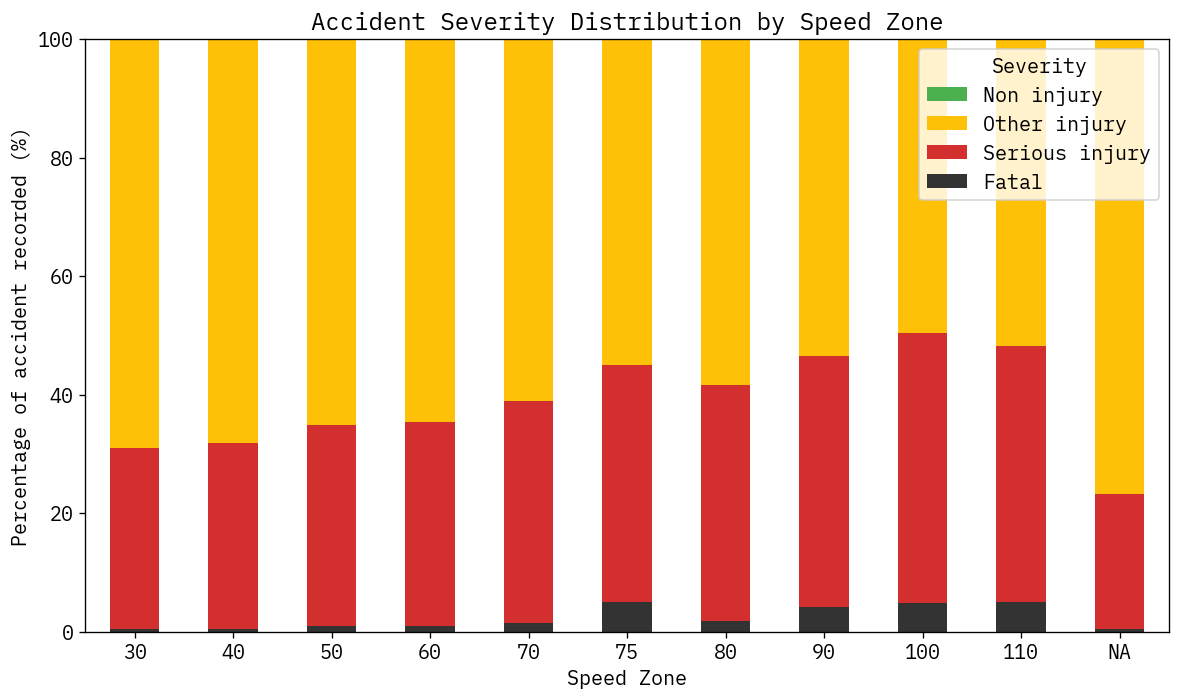

In [7]:
spd_plot = (
    df["SPEED_ZONE"]
    .astype("Int64")
    .astype("string")
    .fillna("NA")
)

sev_labels = {
    1: "Fatal",
    2: "Serious injury",
    3: "Other injury",
    4: "Non injury",
}

sev_plot = df["SEVERITY"].map(sev_labels)

sev_by_spd = pd.crosstab(
    spd_plot,
    sev_plot,
    normalize="index"
) * 100


sev_by_spd = sev_by_spd.loc[
    sorted(sev_by_spd.index, key=lambda x: 999 if x == "NA" else int(x))
]

stack_order = list(sev_labels.values())
legend_order = stack_order[::-1]

sev_by_spd = sev_by_spd[
    [col for col in stack_order if col in sev_by_spd.columns]
]

sev_colors = {
    "Non injury": "#4CAF50",
    "Other injury": "#FFC107",
    "Serious injury": "#D32F2F",
    "Fatal": "#333333",
}

colors = [sev_colors[col] for col in sev_by_spd.columns]

ax = sev_by_spd.plot(kind="bar", stacked=True, figsize=(10, 6), color=colors)
plt.xlabel("Speed Zone")
plt.ylabel("Percentage of accident recorded (%)")
plt.title("Accident Severity Distribution by Speed Zone")
plt.xticks(rotation=0)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    title="Severity"
)
plt.tight_layout()
plt.savefig("sev_by_spd.png", dpi=300)
plt.show()

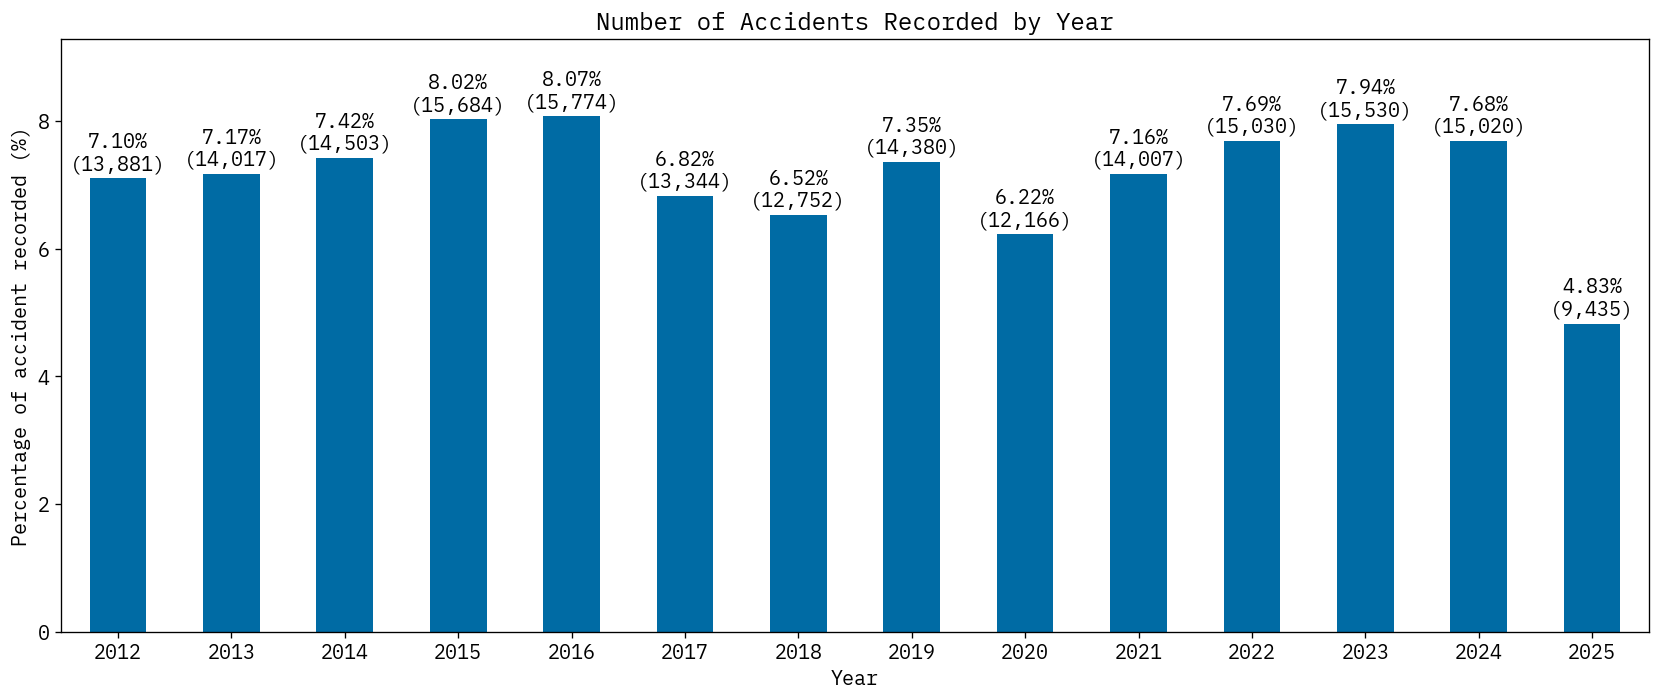

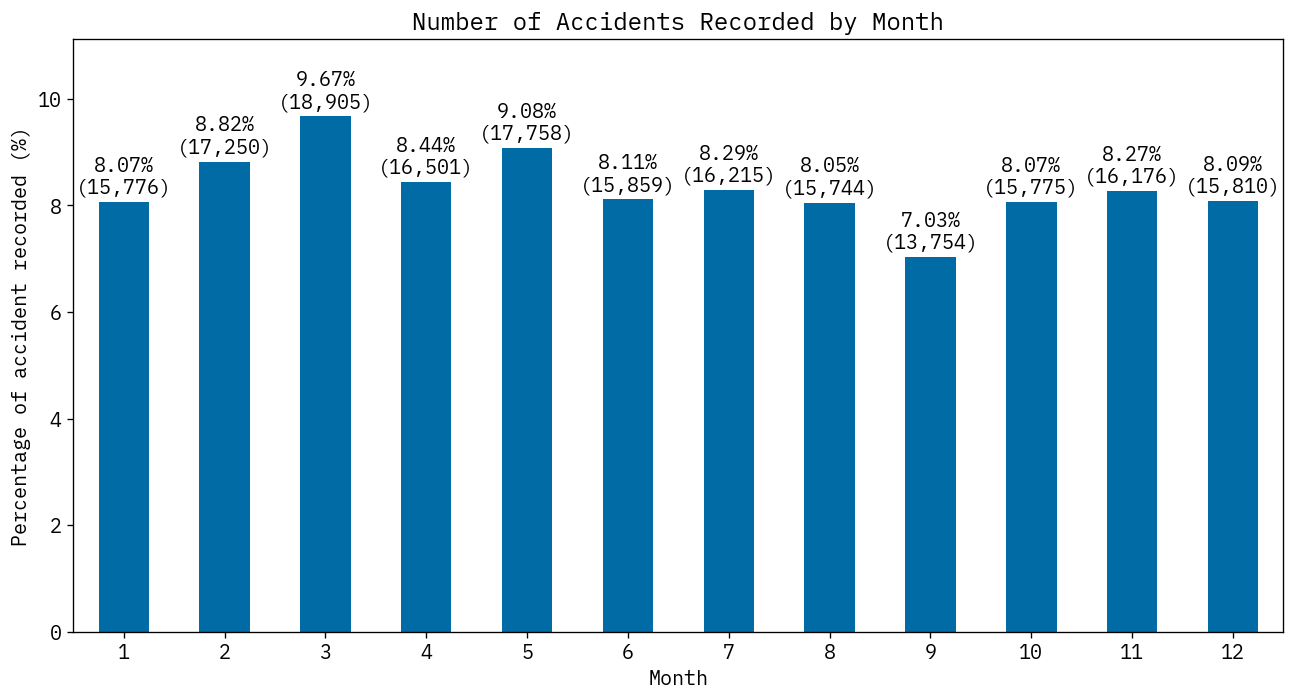

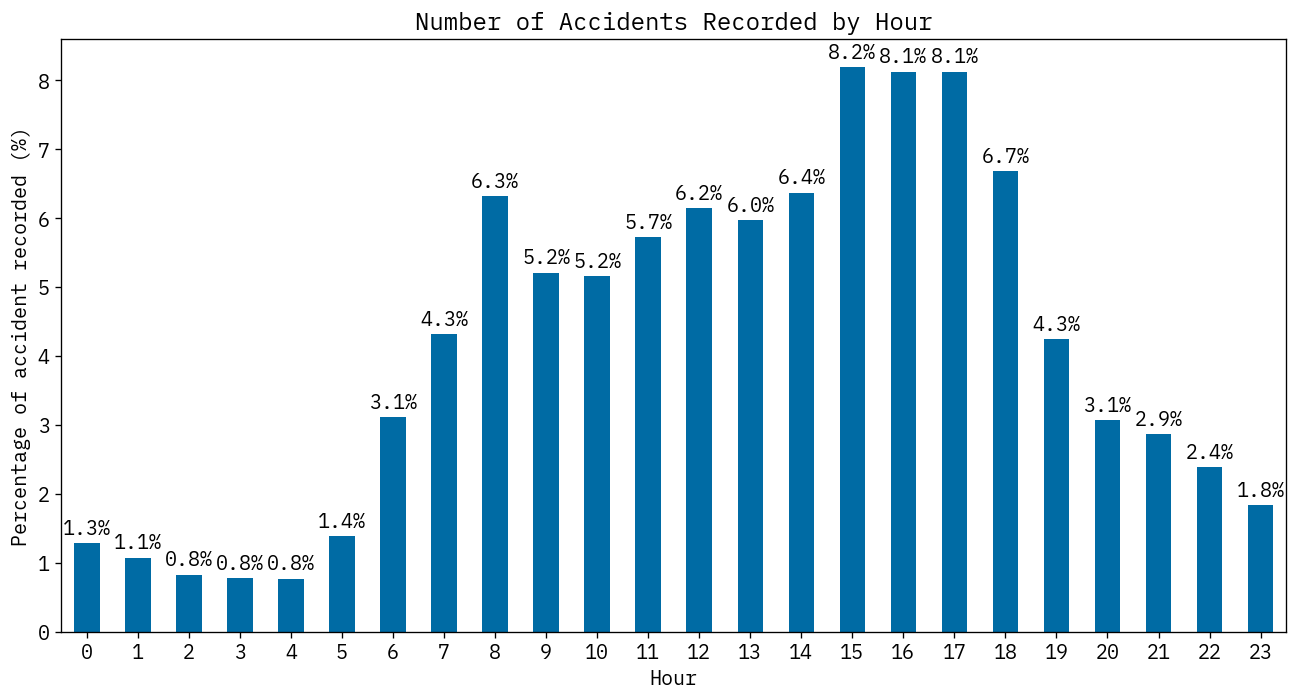

In [8]:
year_counts = df["ACCIDENT_YEAR"].value_counts().sort_index()
month_counts = df["ACCIDENT_MONTH"].value_counts().sort_index()
hour_counts = df["ACCIDENT_HOUR"].value_counts().sort_index()

year_pct = df["ACCIDENT_YEAR"].value_counts(normalize=True).sort_index() * 100
month_pct = df["ACCIDENT_MONTH"].value_counts(normalize=True).sort_index() * 100
hour_pct = df["ACCIDENT_HOUR"].value_counts(normalize=True).sort_index() * 100

# Year
plt.figure(figsize=(14, 6))
ax = year_pct.plot(kind="bar")
ax.bar_label(
    ax.containers[0],
    labels=[f"{year_pct.values[i]:.2f}%\n({int(year_counts.values[i]):,})" for i in range(len(year_counts.values))],
    padding=3
)
ax.set_ylim(0, year_pct.max() * 1.15)
plt.xlabel("Year")
plt.ylabel("Percentage of accident recorded (%)")
plt.title("Number of Accidents Recorded by Year")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Month
plt.figure(figsize=(11, 6))
ax = month_pct.plot(kind="bar")
ax.bar_label(
    ax.containers[0],
    labels=[f"{month_pct.values[i]:.2f}%\n({int(month_counts.values[i]):,})" for i in range(len(month_counts.values))],
    padding=3
)
ax.set_ylim(0, month_pct.max() * 1.15)
plt.xlabel("Month")
plt.ylabel("Percentage of accident recorded (%)")
plt.title("Number of Accidents Recorded by Month")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Hour
plt.figure(figsize=(11, 6))
ax = hour_pct.plot(kind="bar")
ax.bar_label(
    ax.containers[0],
    labels=[f"{hour_pct.values[i]:.1f}%" for i in range(len(hour_counts.values))],
    padding=3
)
plt.xlabel("Hour")
plt.ylabel("Percentage of accident recorded (%)")
plt.title("Number of Accidents Recorded by Hour")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Chi-2 Test

In [9]:
# Speed to Severity
attrs_to_test = ["SPEED_ZONE", "ACCIDENT_TYPE", "DCA_CODE", "LIGHT_CONDITION", "ROAD_GEOMETRY", "NODE_TYPE", "DEG_URBAN_NAME", "ROAD_TYPE", 
"atmos_raining", "surface_wet", "vehicle_type_Car", "vehicle_type_Bicycle", "vehicle_type_Motor Cycle", "vehicle_type_Heavy Vehicle (Rigid) > 4.5 Tonnes"]

for attr in attrs_to_test:
    print(f"{attr} to SEVERITY")
    c = pd.crosstab(df[attr], df["SEVERITY"])
    chi2, p, dof, expected = chi2_contingency(c)
    n = c.to_numpy().sum()
    r, c = c.shape
    cramers_v = np.sqrt(chi2 / (n * (min(r, c) - 1)))
    print("Chi-square statistic:", chi2)
    print("p-value:", p)
    print("Degrees of freedom:", dof)
    print("Cramer's V:", cramers_v)
    print()

SPEED_ZONE to SEVERITY
Chi-square statistic: 3967.015317441881
p-value: 0.0
Degrees of freedom: 27
Cramer's V: 0.08546251023372885

ACCIDENT_TYPE to SEVERITY
Chi-square statistic: 5441.673654677899
p-value: 0.0
Degrees of freedom: 24
Cramer's V: 0.09631783076663637

DCA_CODE to SEVERITY
Chi-square statistic: 12202.781042070994
p-value: 0.0
Degrees of freedom: 240
Cramer's V: 0.14423473331472955

LIGHT_CONDITION to SEVERITY
Chi-square statistic: 2914.9782272056786
p-value: 0.0
Degrees of freedom: 18
Cramer's V: 0.07049496579743886

ROAD_GEOMETRY to SEVERITY
Chi-square statistic: 1081.5018171060765
p-value: 4.222668992977742e-213
Degrees of freedom: 24
Cramer's V: 0.04293921230324358

NODE_TYPE to SEVERITY
Chi-square statistic: 756.6429922770067
p-value: 3.581374805258066e-160
Degrees of freedom: 6
Cramer's V: 0.043988295739019745

DEG_URBAN_NAME to SEVERITY
Chi-square statistic: 3972.04007478173
p-value: 0.0
Degrees of freedom: 21
Cramer's V: 0.08248135683646632

ROAD_TYPE to SEVERITY
C

### Logistic Regression

In [10]:
def evaluate_model(name, model, X_test, y_test, threshold=0.5):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)
    
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "pr_auc": average_precision_score(y_test, y_prob),
        "balanced accuracy": balanced_accuracy_score(y_test, y_pred)
    }

### SPEED_ZONE as number or category
This codeblock compares performance of same LR model on same dataset which one treats SPEED_ZONE as categories, the other treats SPEED_ZONE as numbers (divide by 10 so one increment corresponds to 10kph increment)

To ensure fairness, NA speed limits (777, 888, 999) are removed for both models

In [11]:
context_features = [
    # Basic info
    'LIGHT_CONDITION', 'NO_OF_VEHICLES', 'ROAD_GEOMETRY', 'SPEED_ZONE',
    'RMA', 'ROAD_TYPE', 'ROAD_TYPE_INT', 'NODE_TYPE', 'DEG_URBAN_NAME',
    'ACCIDENT_YEAR', 'ACCIDENT_MONTH', 'ACCIDENT_HOUR',
    
    # Weather
    'atmos_clear', 'atmos_not_known', 'atmos_strong_winds', 'atmos_raining',
    'atmos_fog', 'atmos_snowing', 'atmos_dust', 'atmos_smoke',
    
    # Road condition
    'surface_dry', 'surface_wet', 'surface_unknown', 
    'surface_muddy', 'surface_icy', 'surface_snowy', 
    
    # Traffic control
    'traffic_control_Flashing lights', 'traffic_control_Giveway sign',
    'traffic_control_No control', 'traffic_control_Other',
    'traffic_control_Out of order', 'traffic_control_Ped. crossing',
    'traffic_control_Ped. lights', 'traffic_control_Police',
    'traffic_control_RX Bells/Lights', 'traffic_control_RX Gates/Booms',
    'traffic_control_RX No control', 'traffic_control_Roundabout',
    'traffic_control_School Flags', 'traffic_control_School No flags',
    'traffic_control_Stop sign', 'traffic_control_Stop-go lights',
    'traffic_control_Unknown'
]


# Drop NA Speed
df = df.dropna(subset=["SPEED_ZONE"]).copy()

X = df[context_features]
y = df["SEVERITY"].isin([1, 2]).astype(int)

cat_missing_cols = [
    "RMA",
    "ROAD_TYPE",
    "ROAD_TYPE_INT",
    "DEG_URBAN_NAME",
    "NODE_TYPE",
]
for col in cat_missing_cols:
    if ("Unknown" not in X[col].cat.categories):
        X[col] = X[col].cat.add_categories("Unknown")
    X[col] = X[col].fillna("Unknown")

X_encoded = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=THE_ANSWER,
    stratify=y
)

X_train_num = X_train.copy()
X_train_num["SPEED_ZONE_10"] = X_train_num["SPEED_ZONE"] / 10
X_train_num.drop(columns=["SPEED_ZONE"], inplace=True)
X_test_num = X_test.copy()
X_test_num["SPEED_ZONE_10"] = X_test_num["SPEED_ZONE"] / 10
X_test_num.drop(columns=["SPEED_ZONE"], inplace=True)

X_train_cat = X_train.copy()
X_train_cat["SPEED_ZONE"] = X_train_cat["SPEED_ZONE"].astype("category")
X_train_cat = pd.get_dummies(X_train_cat, drop_first=True)
X_test_cat = X_test.copy()
X_test_cat["SPEED_ZONE"] = X_test_cat["SPEED_ZONE"].astype("category")
X_test_cat = pd.get_dummies(X_test_cat, drop_first=True)


lr_cat_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

lr_num_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

lr_cat_model.fit(X_train_cat, y_train)
lr_num_model.fit(X_train_num, y_train)

results = pd.DataFrame([
    evaluate_model("SPEED_ZONE categorical", lr_cat_model, X_test_cat, y_test),
    evaluate_model("SPEED_ZONE numeric", lr_num_model, X_test_num, y_test),
])

print(results)


                    model  accuracy  precision    recall        f1   roc_auc  \
0  SPEED_ZONE categorical  0.577713   0.465215  0.601540  0.524667  0.616299   
1      SPEED_ZONE numeric  0.576498   0.464085  0.601468  0.523920  0.616084   

     pr_auc  balanced accuracy  
0  0.482072           0.582092  
1  0.481757           0.581087  


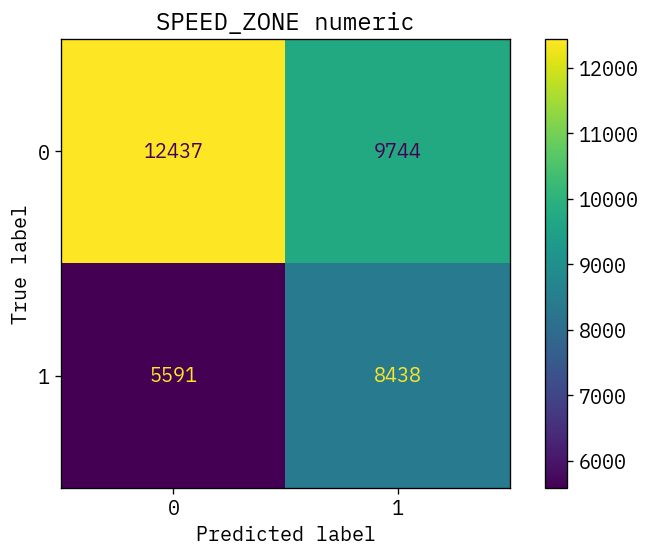

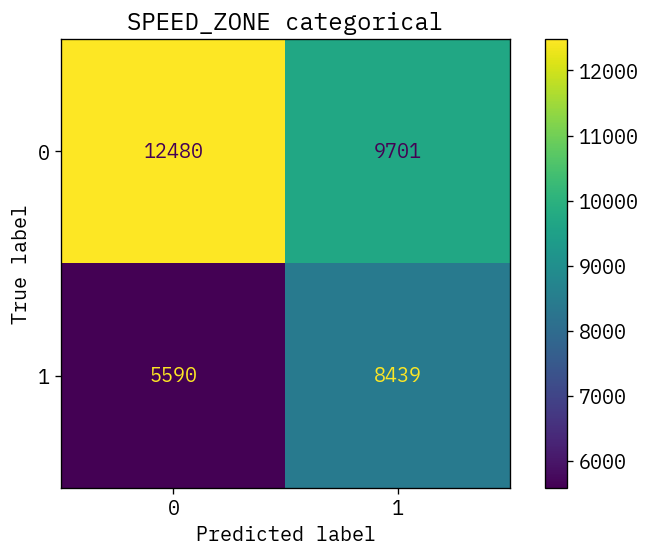

In [12]:
for name, model, X_test in [
    ("SPEED_ZONE numeric", lr_num_model, X_test_num),
    ("SPEED_ZONE categorical", lr_cat_model, X_test_cat),
]:
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(cm)
    disp.plot()

    plt.title(name)
    plt.tight_layout()
    plt.show()

### Find the best threshold
This is just for the sake of seeing how much can be improved but the result is not used in further study

In [13]:
y_prob = lr_cat_model.predict_proba(X_test_cat)[:, 1]
threshold_results = []

for threshold in np.arange(0.05, 0.95, 0.01):
    y_pred_t = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_t, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[threshold_df["f1"].idxmax()]

print(best_row)

threshold    0.390000
precision    0.412200
recall       0.924300
f1           0.570141
Name: 34, dtype: float64


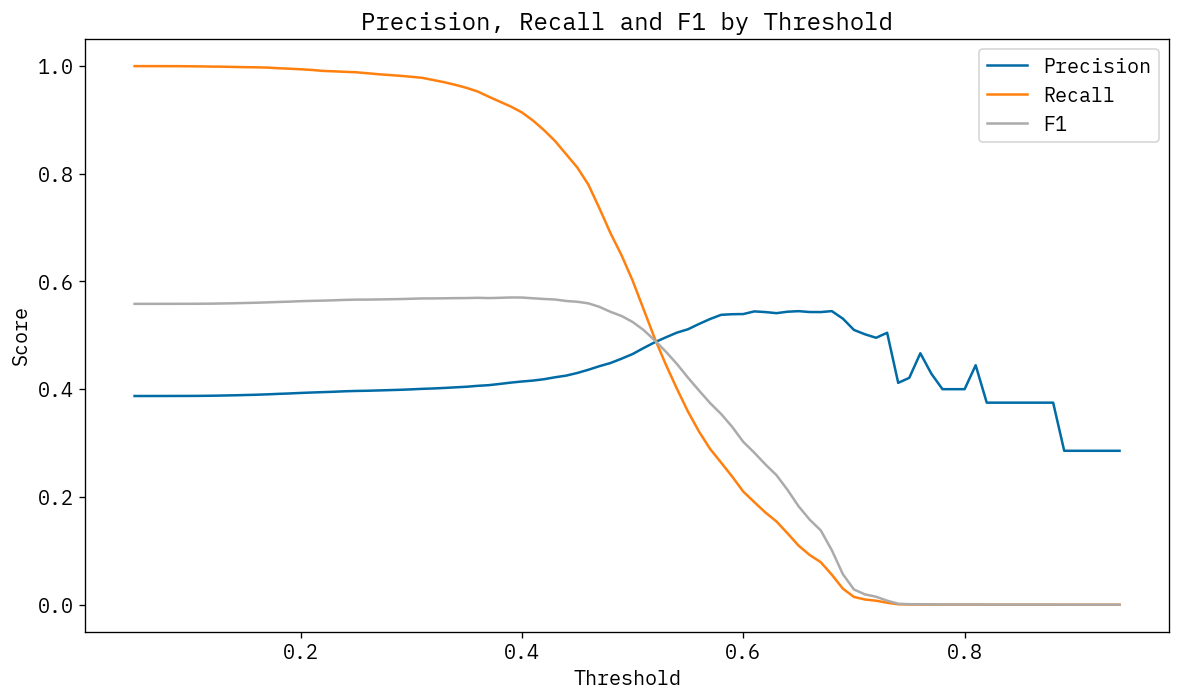

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 by Threshold")
plt.legend()

plt.tight_layout()
plt.show()

### LR Ablation
This codeblock uses **Categorical SPEED_ZONE** and compare:
- How vehicle data, driving intention data affect performance
- How SPEED_ZONE data affect performance

This will train 6 models.

In [15]:
context_features = [
    # Basic info
    'LIGHT_CONDITION', 'NO_OF_VEHICLES', 'ROAD_GEOMETRY', 'SPEED_ZONE',
    'RMA', 'ROAD_TYPE', 'ROAD_TYPE_INT', 'NODE_TYPE', 'DEG_URBAN_NAME',
    'ACCIDENT_YEAR', 'ACCIDENT_MONTH', 'ACCIDENT_HOUR',
    
    # Weather
    'atmos_clear', 'atmos_not_known', 'atmos_strong_winds', 'atmos_raining',
    'atmos_fog', 'atmos_snowing', 'atmos_dust', 'atmos_smoke',
    
    # Road conditoin
    'surface_dry', 'surface_wet', 'surface_unknown', 
    'surface_muddy', 'surface_icy', 'surface_snowy', 
    
    # Traffic control
    'traffic_control_Flashing lights', 'traffic_control_Giveway sign',
    'traffic_control_No control', 'traffic_control_Other',
    'traffic_control_Out of order', 'traffic_control_Ped. crossing',
    'traffic_control_Ped. lights', 'traffic_control_Police',
    'traffic_control_RX Bells/Lights', 'traffic_control_RX Gates/Booms',
    'traffic_control_RX No control', 'traffic_control_Roundabout',
    'traffic_control_School Flags', 'traffic_control_School No flags',
    'traffic_control_Stop sign', 'traffic_control_Stop-go lights',
    'traffic_control_Unknown'
]
vehicle_features = [
    'vehicle_type_Bicycle',
    'vehicle_type_Bus/Coach', 'vehicle_type_Car',
    'vehicle_type_Electric Device',
    'vehicle_type_Heavy Vehicle (Rigid) > 4.5 Tonnes',
    'vehicle_type_Horse (ridden or drawn)',
    'vehicle_type_Light Commercial Vehicle (Rigid) <= 4.5 Tonnes GVM',
    'vehicle_type_Mini Bus(9-13 seats)', 'vehicle_type_Moped',
    'vehicle_type_Motor Cycle', 'vehicle_type_Motor Scooter',
    'vehicle_type_Not Applicable', 'vehicle_type_Not Known',
    'vehicle_type_Other Vehicle', 'vehicle_type_Panel Van',
    'vehicle_type_Parked trailers',
    'vehicle_type_Plant machinery and Agricultural equipment',
    'vehicle_type_Prime Mover (No of Trailers Unknown)',
    'vehicle_type_Prime Mover - Single Trailer',
    'vehicle_type_Prime Mover B-Double',
    'vehicle_type_Prime Mover B-Triple', 'vehicle_type_Prime Mover Only',
    'vehicle_type_Quad Bike', 'vehicle_type_Rigid Truck(Weight Unknown)',
    'vehicle_type_Station Wagon', 'vehicle_type_Taxi', 'vehicle_type_Train',
    'vehicle_type_Tram', 'vehicle_type_Utility'
]
intent_features = [
    'intent_avoiding_animals',
    'intent_changing_lanes', 'intent_going_straight',
    'intent_leaving_driveway', 'intent_merging', 'intent_missing',
    'intent_not_known', 'intent_other_stationary', 'intent_out_of_control',
    'intent_overtaking', 'intent_parked_illegally', 'intent_parked_legally',
    'intent_parking_or_unparking', 'intent_reversing',
    'intent_slow_or_stopping', 'intent_stationary_accident',
    'intent_stationary_broken_down', 'intent_turning_left',
    'intent_turning_right', 'intent_u_turn', 'intent_wrong_way'
]

# Fresh data
df = pd.read_parquet("rq1.parquet")

# Binary outcome T = Fatal or severe, F = other or no injury
df["SEVERITY"] = df["SEVERITY"].isin([1, 2]).astype(int)
# Convert speed zone to categotical
df["SPEED_ZONE"] = df["SPEED_ZONE"].astype("category")

cat_missing_cols = [
    "SPEED_ZONE",
    "RMA",
    "ROAD_TYPE",
    "ROAD_TYPE_INT",
    "DEG_URBAN_NAME",
    "NODE_TYPE",
]

# Fill missing cols with Unknown
for col in cat_missing_cols:
    if ("Unknown" not in df[col].cat.categories):
        df[col] = df[col].cat.add_categories("Unknown")
    df[col] = df[col].fillna("Unknown")

# Split into same dataset for each variant
y = df["SEVERITY"].copy()
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=THE_ANSWER,
    stratify=y
)

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

ctx_cols = context_features
veh_cols = context_features + vehicle_features
full_cols = context_features + vehicle_features + intent_features

# Encode one-hot
X_train_ctx = df.loc[train_idx, ctx_cols].copy()
X_test_ctx = df.loc[test_idx, ctx_cols].copy()
X_train_veh = df.loc[train_idx, veh_cols].copy()
X_test_veh = df.loc[test_idx, veh_cols].copy()
X_train_full = df.loc[train_idx, full_cols].copy()
X_test_full = df.loc[test_idx, full_cols].copy()

def onehot_train_test(X_train, X_test):
    """
    Encode one-hot for X_train and X_test at the same time aligned
    """
    X_train_enc = pd.get_dummies(X_train, drop_first=True)
    X_test_enc = pd.get_dummies(X_test, drop_first=True)

    X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

    return X_train_enc, X_test_enc

X_train_ctx, X_test_ctx = onehot_train_test(X_train_ctx, X_test_ctx)
X_train_veh, X_test_veh = onehot_train_test(X_train_veh, X_test_veh)
X_train_full, X_test_full = onehot_train_test(X_train_full, X_test_full)

print("ctx:", X_train_ctx.shape)
print("veh:", X_train_veh.shape)
print("full:", X_train_full.shape)

print("ctx extra speed cols:", [c for c in X_train_ctx.columns if c.startswith("SPEED_ZONE_")])
print("veh extra cols:", len(set(X_train_veh.columns) - set(X_train_ctx.columns)))
print("full extra cols:", len(set(X_train_full.columns) - set(X_train_veh.columns)))

models: dict[str, tuple[Pipeline, pd.DataFrame]] = {}
# Train models
for name, X_train, X_test in [
    ("Context only", X_train_ctx, X_test_ctx), 
    ("Context + vehicle", X_train_veh, X_test_veh), 
    ("Full", X_train_full, X_test_full)]:
    for remove_spd in [True, False]:
        lr = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(
                max_iter=10000,
                class_weight="balanced",
                solver="lbfgs"
            ))
        ])
        X_train_this = X_train.copy()
        X_test_this = X_test.copy()
        if (remove_spd):
            speed_cols = [col for col in X_train.columns if col.startswith("SPEED_ZONE_")]
            X_train_this.drop(columns=speed_cols, inplace=True)
            speed_cols = [col for col in X_test.columns if col.startswith("SPEED_ZONE_")]
            X_test_this.drop(columns=speed_cols, inplace=True)
        print(f"Training model: {name} {"no" if remove_spd else "with"} SPEED_ZONE")
        lr.fit(X_train_this, y_train)
        models[f"{name} {"no" if remove_spd else "with"} SPEED_ZONE"] = (lr, X_test_this)

evals = []
for name, v in models.items():
    model, X_test = v
    evals.append(evaluate_model(name, model, X_test, y_test))

print(pd.DataFrame(evals))

ctx: (156418, 255)
veh: (156418, 284)
full: (156418, 305)
ctx extra speed cols: ['SPEED_ZONE_40.0', 'SPEED_ZONE_50.0', 'SPEED_ZONE_60.0', 'SPEED_ZONE_70.0', 'SPEED_ZONE_75.0', 'SPEED_ZONE_80.0', 'SPEED_ZONE_90.0', 'SPEED_ZONE_100.0', 'SPEED_ZONE_110.0', 'SPEED_ZONE_Unknown']
veh extra cols: 29
full extra cols: 21
Training model: Context only no SPEED_ZONE
Training model: Context only with SPEED_ZONE
Training model: Context + vehicle no SPEED_ZONE
Training model: Context + vehicle with SPEED_ZONE
Training model: Full no SPEED_ZONE
Training model: Full with SPEED_ZONE
                               model  accuracy  precision    recall        f1  \
0         Context only no SPEED_ZONE  0.572535   0.451278  0.635485  0.527770   
1       Context only with SPEED_ZONE  0.578929   0.456286  0.627390  0.528330   
2    Context + vehicle no SPEED_ZONE  0.594783   0.469969  0.610586  0.531128   
3  Context + vehicle with SPEED_ZONE  0.601227   0.476233  0.610041  0.534896   
4                 Full

### Random Forest

In [16]:
# Fresh data
df = pd.read_parquet("rq1.parquet")
